<a href="https://colab.research.google.com/github/trish272000/Thesis/blob/main/notebooks/04_decisions_under_uncertainty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04 — Decisions Under Uncertainty
**Thesis:** Uncertainty-Aware Carbon Digital Twin for Sustainable Industrial Systems

The twin now turns its forecasts into **decisions**. Each evening it decides for tomorrow:

1. **When to run the flexible load** (load scheduling against the time-of-day tariff and the hourly grid carbon).
2. **What share of tomorrow's electricity to buy as green power**, so that emissions stay under the daily limit.

| Part | What happens |
|---|---|
| 1 | Costs: green power premium per tonne avoided, and the CCTS penalty for crossing the limit |
| 2 | Combine forecast uncertainty with emission-factor uncertainty (simulation) |
| 3 | Compare six ways of buying green power over the test period, across 500 possible emission-factor years |
| 4 | The cost-optimal confidence level (newsvendor rule) and how it depends on the penalty |
| 5 | Flexible-load scheduling: cost-only vs carbon-aware |
| 6 | Summary table and the main trade-off figure for the thesis |

No GPU is needed.

## Part 0 — Setup

In [1]:
import sys, os, json
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/thesis"
else:
    BASE = os.environ.get("THESIS_BASE", os.path.abspath("thesis"))
PROC, FIGS, RES = f"{BASE}/data/processed", f"{BASE}/results/figures", f"{BASE}/results"
CONFIG = json.load(open(f"{BASE}/config.json"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linprog

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RNG = np.random.default_rng(42)
ALPHA = 1 - CONFIG["confidence"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGS}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

Mounted at /content/drive


## Part 1 — What things cost

**Green power.** Rs 0.34 extra per kWh (UP green tariff; same as the REC price of Rs 340 per MWh).
Converted to **rupees per tonne of CO₂ avoided** using the plant's own emission factor.

**Crossing the limit.** Under the *Greenhouse Gases Emission Intensity Target Rules, 2025* (CCTS), a plant that misses its
target must surrender carbon credit certificates for the shortfall; if it does not, it pays **environmental
compensation equal to twice the average certificate price**. Indian certificates were expected to start at about
**US$10 per tonne** (≈ Rs 900). So:

| Case | Cost per tonne over the limit |
|---|---|
| Buy certificates for the shortfall | Rs 900 |
| **Environmental compensation (main case)** | **Rs 1,800** |

Note: CCTS compliance is checked over a year. Here every day is treated as its own small compliance check, which is a
stricter, operational version of the same rule.

In [2]:
CCC_PRICE = 900.0                       # Rs per tonne (≈ US$10)
PENALTY = 2 * CCC_PRICE                 # Rs per tonne over the limit (environmental compensation)
CONFIG.update({"ccc_price_rs_per_t": CCC_PRICE, "penalty_rs_per_t": PENALTY})
json.dump(CONFIG, open(f"{BASE}/config.json", "w"), indent=2)

daily = pd.read_parquet(f"{PROC}/steel_daily.parquet")[["day", "kwh", "co2_t", "cost_rs"]]
ef_stats = json.load(open(f"{PROC}/grid_ef_stats.json"))
EF_MEAN, EF_STD, EF_MIN, EF_MAX = (ef_stats[k] for k in ["ef_mean", "ef_std", "ef_min", "ef_max"])

ef_eff = (daily["co2_t"] / (daily["kwh"] / 1000)).median()     # plant's own tCO2 per MWh (hourly-weighted)
PREMIUM = CONFIG["green_premium_rs_per_kwh"]
GREEN_PER_T = PREMIUM * 1000 / ef_eff                           # Rs per tonne avoided
print(f"Plant emission factor ≈ {ef_eff:.3f} tCO2/MWh")
print(f"Green power: Rs {GREEN_PER_T:,.0f} per tonne avoided | penalty: Rs {PENALTY:,.0f} per tonne over the limit")
print(f"Cost-optimal confidence level (newsvendor): 1 - green/penalty = {1 - GREEN_PER_T / PENALTY:.0%}")

Plant emission factor ≈ 0.656 tCO2/MWh
Green power: Rs 518 per tonne avoided | penalty: Rs 1,800 per tonne over the limit
Cost-optimal confidence level (newsvendor): 1 - green/penalty = 71%


**The newsvendor rule.** Buying one extra tonne of green cover costs the green price *for sure*; not buying it costs the
penalty *only if* emissions turn out high. The cheapest plan on average covers emissions up to the level where
P(emissions ≤ cover) = 1 − green price ÷ penalty. With a 95% target the plant is choosing to be *more* careful than pure
cost would suggest, which is a compliance choice. Part 4 shows the cost of each choice.

## Part 2 — Combining forecast and emission-factor uncertainty
* **Forecast uncertainty:** the LSTM ensemble's samples from notebook 03, stretched by one calibration factor so that its
  95% upper bound holds on the checking period (same conformal idea, applied to the whole distribution).
* **Emission-factor uncertainty:** the year's grid factor is unknown (CEA recent years: mean 0.711, spread 0.019).
  Each simulated *year* draws one factor, shared by all days of that year.

In [3]:
U = {k: pd.read_parquet(f"{PROC}/uq_daily_{k}.parquet") for k in ["A", "B", "C"]}
SAMPLES = np.load(f"{PROC}/uq_samples_C.npy")                      # (days, samples) daily tCO2, raw
C = U["C"].merge(daily[["day", "kwh"]], on="day", how="left")
med = np.median(SAMPLES, axis=1)
up_raw = np.quantile(SAMPLES, 1 - ALPHA, axis=1)

# Calibration factor s: on checking days, how far (in units of the raw upper spread) did actuals go?
cal = (C["role"] == "calib").values
score = (C["co2"].values[cal] - med[cal]) / np.clip(up_raw[cal] - med[cal], 1e-6, None)
n = cal.sum()
s = np.quantile(score, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n), method="higher")
SAMPLES_CAL = med[:, None] + s * (SAMPLES - med[:, None])
SAMPLES_CAL = np.clip(SAMPLES_CAL, 0, None)
print(f"Spread stretch factor s = {s:.2f}")

# Emission-factor years
K = 500
a, b = (EF_MIN - EF_MEAN) / EF_STD, (EF_MAX - EF_MEAN) / EF_STD
EF_YEARS = stats.truncnorm.rvs(a, b, loc=EF_MEAN, scale=EF_STD, size=K, random_state=RNG) / EF_MEAN   # ratio to mean

# Full predictive distribution for each day: forecast samples x emission-factor ratio
m = SAMPLES_CAL.shape[1]
ef_mix = RNG.choice(EF_YEARS, size=SAMPLES_CAL.shape)
FULL = SAMPLES_CAL * ef_mix

T = (C["role"] == "test").values
y = C["co2"].values
for label, X in [("forecast only", SAMPLES_CAL), ("forecast + emission factor", FULL)]:
    upb = np.quantile(X, 1 - ALPHA, axis=1)
    print(f"{label:28s}: mean 95% upper bound {upb[T].mean():.3f} t | test days above it {100*np.mean(y[T] > upb[T]):.1f}%")

Spread stretch factor s = 2.78
forecast only               : mean 95% upper bound 2.871 t | test days above it 0.0%
forecast + emission factor  : mean 95% upper bound 2.856 t | test days above it 0.0%


Share of total daily emission uncertainty coming from the emission factor: 0.2%


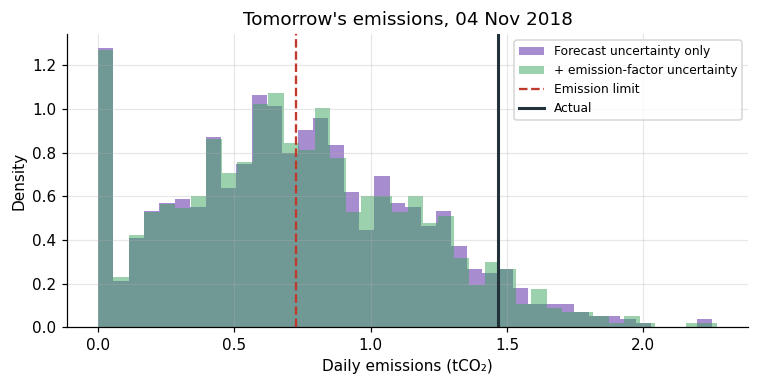

In [4]:
# Exact variance of (forecast x factor ratio) for independent parts, so simulation noise does not blur it
vX, mX = SAMPLES_CAL[T].var(axis=1), SAMPLES_CAL[T].mean(axis=1)
vR, mR = EF_YEARS.var(), EF_YEARS.mean()
v_full = vX * (vR + mR**2) + mX**2 * vR
extra = np.mean(v_full - vX * mR**2) / np.mean(v_full)
print(f"Share of total daily emission uncertainty coming from the emission factor: {extra:.1%}")

fig, ax = plt.subplots(figsize=(7, 3.6))
d0 = int(np.argmax(T)) + 3
ax.hist(SAMPLES_CAL[d0], bins=40, alpha=0.6, color="#6C3FB0", density=True, label="Forecast uncertainty only")
ax.hist(FULL[d0], bins=40, alpha=0.5, color="#3BA55C", density=True, label="+ emission-factor uncertainty")
ax.axvline(C["cap_t"].iloc[d0], color="#C0392B", ls="--", label="Emission limit")
ax.axvline(y[d0], color="#23313B", lw=2, label="Actual")
ax.set(xlabel="Daily emissions (tCO₂)", ylabel="Density", title=f"Tomorrow's emissions, {C['day'].iloc[d0]:%d %b %Y}")
ax.legend(fontsize=8)
savefig("04_combined_uncertainty")

## Part 3 — Six ways to buy green power (test period, November–December)
Each plan chooses a green share *f* for every day **the evening before**. Then each of the 500 simulated
emission-factor years is played out.

| Plan | Rule for tomorrow's green share |
|---|---|
| 1. No action | *f* = 0 |
| 2. Single forecast | cover the XGBoost forecast exactly (notebook 02) |
| 3. Fixed worst case | cover the forecast plus the **largest** error seen on the checking days |
| 4. Risk-aware 95% (low–high XGBoost) | cover the calibrated 95% upper bound (method B) |
| 5. Risk-aware 95% (LSTM ensemble + emission factor) | cover the 95% upper bound of the combined distribution |
| 6. Cost-optimal (LSTM ensemble + emission factor) | choose *f* that minimises expected green cost + penalty |
| Reference: perfect knowledge | cover the actual emissions exactly |

Rule for plans 2–5: *f* = max(0, 1 − limit ÷ planned emissions).

In [5]:
TEST = C[T].reset_index(drop=True)
cap = TEST["cap_t"].values
kwh = TEST["kwh"].values
y_t = TEST["co2"].values
A_t = U["A"].set_index("day").loc[TEST["day"]]
B_t = U["B"].set_index("day").loc[TEST["day"]]
A_c = U["A"][U["A"].role == "calib"]

def share_for(plan_emissions):
    return np.clip(1 - cap / np.clip(plan_emissions, 1e-6, None), 0, 1)

worst_err = (A_c["co2"] - A_c["point"]).max()
FULL_T = FULL[T]

def optimal_share(Xs, penalty, kwh_fc):
    grid = np.linspace(0, 1, 101)
    best = np.empty(len(Xs))
    for i in range(len(Xs)):
        over = np.clip((1 - grid[:, None]) * Xs[i][None, :] - cap[i], 0, None).mean(axis=1)
        total = grid * kwh_fc[i] * PREMIUM + penalty * over
        best[i] = grid[np.argmin(total)]
    return best

kwh_fc = FULL_T.mean(axis=1) / ef_eff * 1000          # expected kWh implied by the forecast

PLANS = {
    "1. No action": np.zeros(len(TEST)),
    "2. Single forecast": share_for(A_t["point"].values),
    "3. Fixed worst case": share_for(A_t["point"].values + worst_err),
    "4. Risk-aware 95% (low–high XGBoost)": share_for(B_t["up"].values),
    "5. Risk-aware 95% (LSTM ens. + EF)": share_for(np.quantile(FULL_T, 1 - ALPHA, axis=1)),
    "6. Cost-optimal (LSTM ens. + EF)": optimal_share(FULL_T, PENALTY, kwh_fc),
}
print("Average green share bought:")
for k, f in PLANS.items():
    print(f"  {k:40s} {f.mean():.1%}")

Average green share bought:
  1. No action                             0.0%
  2. Single forecast                       6.2%
  3. Fixed worst case                      37.9%
  4. Risk-aware 95% (low–high XGBoost)     38.2%
  5. Risk-aware 95% (LSTM ens. + EF)       41.1%
  6. Cost-optimal (LSTM ens. + EF)         28.2%


In [6]:
def play_out(f, perfect=False):
    # Evaluate a plan over K emission-factor years. Returns averages per year.
    res = []
    for r in EF_YEARS:
        actual = y_t * r
        ff = np.clip(1 - cap / actual, 0, 1) if perfect else f
        realised = (1 - ff) * actual
        over_t = np.clip(realised - cap, 0, None)
        over = over_t > cap * 1e-4
        green = (ff * kwh * PREMIUM).sum()
        pen = PENALTY * over_t.sum()
        res.append([100 * over.mean(), over_t.sum(), green, pen, green + pen])
    return np.array(res)

rows, dist = {}, {}
for k, f in PLANS.items():
    r = play_out(f); dist[k] = r
    rows[k] = r.mean(axis=0)
r = play_out(None, perfect=True); dist["Perfect knowledge"] = r
rows["Perfect knowledge"] = r.mean(axis=0)
SUMMARY = pd.DataFrame(rows, index=["days over limit (%)", "tonnes over limit", "green power cost (Rs)",
                                    "penalty (Rs)", "total cost (Rs)"]).T
SUMMARY["days over limit, worst year (%)"] = [np.percentile(dist[k][:, 0], 95) for k in SUMMARY.index]
SUMMARY.to_csv(f"{RES}/04_plan_comparison.csv")
print(SUMMARY.round(1).to_string())

                                      days over limit (%)  tonnes over limit  green power cost (Rs)  penalty (Rs)  total cost (Rs)  days over limit, worst year (%)
1. No action                                         35.9                9.2                    0.0       16595.0          16595.0                             42.6
2. Single forecast                                   33.2                6.7                 2031.6       12102.5          14134.1                             37.7
3. Fixed worst case                                   1.8                0.0                16872.6          79.6          16952.2                              4.9
4. Risk-aware 95% (low–high XGBoost)                  3.1                0.1                15849.3         198.8          16048.1                              4.9
5. Risk-aware 95% (LSTM ens. + EF)                    0.2                0.0                19487.2           0.4          19487.6                              1.6
6. Cost-optimal 

**How to read this.**
* *Days over limit* is averaged over the 500 emission-factor years; the last column shows a bad year (95th percentile).
* *Total cost* = green power + penalties. The energy bill itself is the same for every plan here (scheduling is Part 5).
* A good plan sits **close to perfect knowledge**: few days over the limit *and* a total cost not much above the
  perfect-knowledge cost.

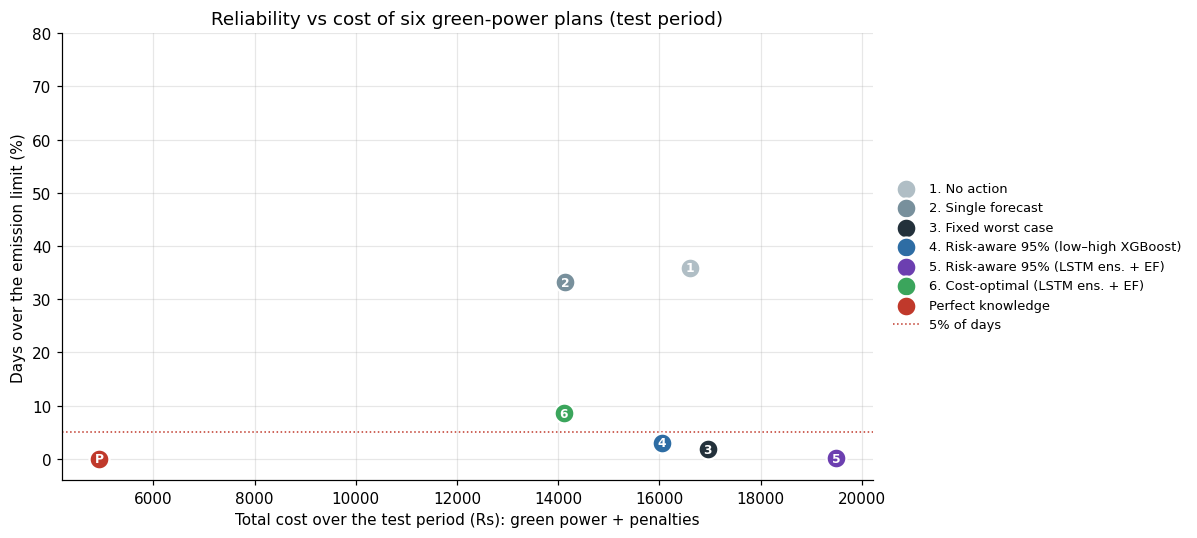

In [7]:
# Main thesis figure: reliability vs cost
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"1": "#B0BEC5", "2": "#78909C", "3": "#23313B", "4": "#2E6DA4", "5": "#6C3FB0", "6": "#3BA55C", "P": "#C0392B"}
for k, row in SUMMARY.iterrows():
    key = k[0] if k[0].isdigit() else "P"
    ax.scatter(row["total cost (Rs)"], row["days over limit (%)"], s=170, color=colors[key], zorder=3,
               edgecolor="white", lw=1.5, label=k)
    ax.annotate(key, (row["total cost (Rs)"], row["days over limit (%)"]), ha="center", va="center",
                fontsize=8, color="white", weight="bold", zorder=4)
ax.axhline(100 * ALPHA, color="#C0392B", ls=":", lw=1, label="5% of days")
ax.set_ylim(-4, max(80, SUMMARY["days over limit (%)"].max() + 5))
ax.set(xlabel="Total cost over the test period (Rs): green power + penalties",
       ylabel="Days over the emission limit (%)",
       title="Reliability vs cost of six green-power plans (test period)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5, frameon=False)
savefig("04_reliability_vs_cost")

## Part 4 — How careful should the plant be?
The cost-optimal plan depends on how large the penalty is. Here the penalty is varied from just the certificate price
(Rs 900) up to ten times the compensation. For each value, plan 6 is re-optimised and compared with the fixed 95% plan.

 penalty (Rs/t)           plan implied confidence level  days over limit (%)  total cost (Rs)
            900   Cost-optimal                      42%                 27.3           8620.5
            900 Risk-aware 95%                      95%                  0.1          19487.3
           1800   Cost-optimal                      71%                  8.6          14105.4
           1800 Risk-aware 95%                      95%                  0.1          19487.5
           3600   Cost-optimal                      86%                  1.7          17764.4
           3600 Risk-aware 95%                      95%                  0.1          19487.9
           9000   Cost-optimal                      94%                  0.0          21491.0
           9000 Risk-aware 95%                      95%                  0.1          19489.0
          18000   Cost-optimal                      97%                  0.0          23574.9
          18000 Risk-aware 95%                      95%     

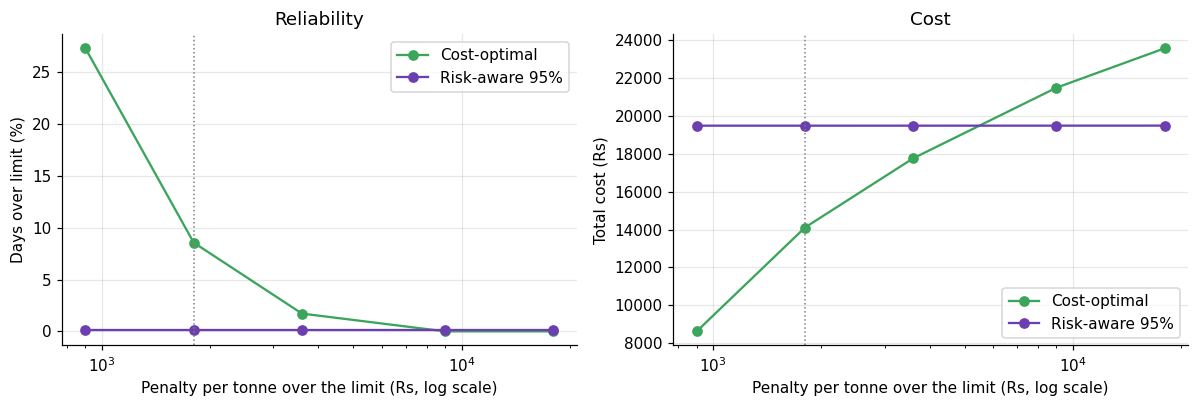

In [8]:
rows = []
for pen in [900, 1800, 3600, 9000, 18000]:
    f_opt = optimal_share(FULL_T, pen, kwh_fc)
    for label, f in [("Cost-optimal", f_opt), ("Risk-aware 95%", PLANS["5. Risk-aware 95% (LSTM ens. + EF)"])]:
        res = []
        for r in EF_YEARS[:200]:
            actual = y_t * r
            over_t = np.clip((1 - f) * actual - cap, 0, None)
            green = (f * kwh * PREMIUM).sum()
            res.append([100 * (over_t > cap * 1e-4).mean(), green + pen * over_t.sum()])
        res = np.mean(res, axis=0)
        rows.append({"penalty (Rs/t)": pen, "plan": label,
                     "implied confidence level": f"{max(0, 1 - GREEN_PER_T / pen):.0%}" if label == "Cost-optimal" else "95%",
                     "days over limit (%)": res[0], "total cost (Rs)": res[1]})
PEN = pd.DataFrame(rows)
PEN.to_csv(f"{RES}/04_penalty_sensitivity.csv", index=False)
print(PEN.round(1).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for label, col in [("Cost-optimal", "#3BA55C"), ("Risk-aware 95%", "#6C3FB0")]:
    p = PEN[PEN.plan == label]
    ax[0].plot(p["penalty (Rs/t)"], p["days over limit (%)"], "o-", color=col, label=label)
    ax[1].plot(p["penalty (Rs/t)"], p["total cost (Rs)"], "o-", color=col, label=label)
for a in ax:
    a.set_xscale("log"); a.set_xlabel("Penalty per tonne over the limit (Rs, log scale)"); a.legend()
    a.axvline(PENALTY, color="grey", ls=":", lw=1)
ax[0].set(ylabel="Days over limit (%)", title="Reliability")
ax[1].set(ylabel="Total cost (Rs)", title="Cost")
savefig("04_penalty_sensitivity")

**Reading the result.** When the penalty is small, the cost-optimal plan accepts more days over the limit because paying
the penalty is cheaper than buying green power. As the penalty rises, it becomes as careful as the 95% plan. The
**break-even penalty** is where the 95% plan is also the cheapest: green price ÷ 0.05 ≈ 20 × green price per tonne.

## Part 5 — Scheduling the flexible load
For every day of 2018, 20% of maximum-load energy may move up to 4 hours earlier or later (same day), without exceeding
the plant's highest hourly load. Three objectives are compared:

| Objective | Moves flexible energy to hours that are… |
|---|---|
| Cost only | cheapest (time-of-day tariff) |
| Carbon only | cleanest (hourly grid factor) |
| Combined | cheapest after adding the green-power price of the carbon (Rs per tonne × hourly factor) |

Each day is a small linear programme (solved with SciPy's HiGHS solver).

In [9]:
steel = pd.read_parquet(f"{PROC}/steel_prepared.parquet")
steel["ts_hour"] = steel["ts"].dt.floor("h")
steel["flex_kwh"] = np.where(steel["load_type"] == "Maximum_Load", CONFIG["flex_share"] * steel["kwh"], 0.0)
Hh = steel.groupby("ts_hour").agg(kwh=("kwh", "sum"), kvah=("kvah", "sum"), flex=("flex_kwh", "sum"),
                                 price=("price_rs_per_kvah", "mean"), ef=("grid_ef_t_per_mwh", "mean"),
                                 split=("split", "first")).reset_index()
Hh["day"] = Hh["ts_hour"].dt.normalize(); Hh["hour"] = Hh["ts_hour"].dt.hour
Hh["ratio"] = np.where(Hh["kwh"] > 1, Hh["kvah"] / Hh["kwh"].clip(lower=1e-6), 1.0).clip(1, 1.5)
KMAX = Hh["kwh"].max()
W = CONFIG["flex_window_h"]

def schedule_day(g, carbon_price):
    g = g.sort_values("hour")
    hrs, flex, base = g["hour"].values, g["flex"].values, (g["kwh"] - g["flex"]).values
    unit_cost = g["price"].values * g["ratio"].values + carbon_price * g["ef"].values / 1000   # Rs per kWh
    pairs = [(i, j) for i in range(len(hrs)) if flex[i] > 0 for j in range(len(hrs)) if abs(hrs[j] - hrs[i]) <= W]
    if not pairs:
        return g["kwh"].values
    c = np.array([unit_cost[j] for _, j in pairs])
    srcs = sorted({i for i, _ in pairs})
    A_eq = np.zeros((len(srcs), len(pairs))); b_eq = np.array([flex[i] for i in srcs])
    for p, (i, j) in enumerate(pairs):
        A_eq[srcs.index(i), p] = 1
    A_ub = np.zeros((len(hrs), len(pairs))); b_ub = KMAX - base
    for p, (i, j) in enumerate(pairs):
        A_ub[j, p] = 1
    sol = linprog(c, A_ub=A_ub, b_ub=np.clip(b_ub, 0, None), A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")
    if not sol.success:
        return g["kwh"].values
    new = base.copy()
    for p, (i, j) in enumerate(pairs):
        new[j] += sol.x[p]
    return new

OBJ = {"As run (no shifting)": None, "Cost only": 0.0, "Carbon only": None, "Combined": GREEN_PER_T}
sched = {}
for name, cp in OBJ.items():
    if name == "As run (no shifting)":
        sched[name] = Hh["kwh"].values
        continue
    out = np.empty(len(Hh))
    for _, g in Hh.groupby("day"):
        if name == "Carbon only":
            out[g.index] = schedule_day(g.assign(price=0.0), carbon_price=1.0)   # only the grid factor matters
        else:
            out[g.index] = schedule_day(g, carbon_price=cp)
    sched[name] = out
print("Schedules computed for", Hh["day"].nunique(), "days")

Schedules computed for 365 days


In [10]:
rows = []
for name, k in sched.items():
    cost = (k * Hh["ratio"] * Hh["price"]).groupby(Hh["split"]).sum()
    co2 = (k / 1000 * Hh["ef"]).groupby(Hh["split"]).sum()
    for sp in ["train", "calib", "test"]:
        rows.append({"objective": name, "period": sp, "energy cost (Rs)": cost[sp], "emissions (t)": co2[sp]})
SCH = pd.DataFrame(rows)
base_ = SCH[SCH.objective == "As run (no shifting)"].set_index("period")
SCH["cost change (%)"] = SCH.apply(lambda r: 100 * (r["energy cost (Rs)"] / base_.loc[r.period, "energy cost (Rs)"] - 1), axis=1)
SCH["emissions change (%)"] = SCH.apply(lambda r: 100 * (r["emissions (t)"] / base_.loc[r.period, "emissions (t)"] - 1), axis=1)
SCH.to_csv(f"{RES}/04_scheduling.csv", index=False)
print(SCH.pivot(index="objective", columns="period", values=["cost change (%)", "emissions change (%)"]).round(2).to_string())

                     cost change (%)             emissions change (%)            
period                         calib  test train                calib  test train
objective                                                                        
As run (no shifting)            0.00  0.00  0.00                 0.00  0.00  0.00
Carbon only                    -0.53 -0.39 -0.71                -0.59 -0.95 -0.66
Combined                       -1.24 -0.76 -1.06                -0.44 -0.72 -0.26
Cost only                      -1.24 -0.76 -1.06                -0.42 -0.65 -0.17


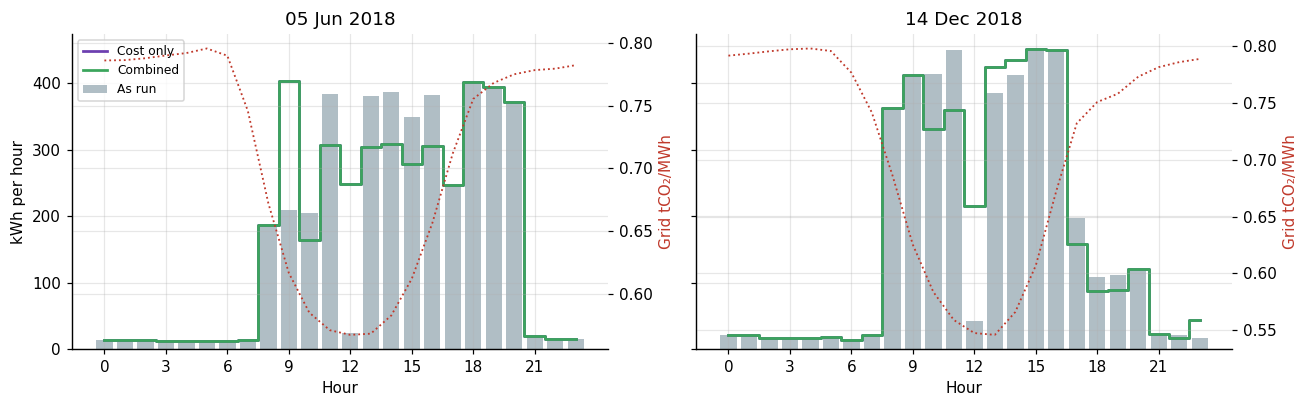

In [11]:
# One summer and one winter work day: before and after
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, month in zip(ax, [6, 12]):
    cand = Hh[(Hh["ts_hour"].dt.month == month)].groupby("day")["flex"].sum()
    day = cand.idxmax()
    g = Hh[Hh["day"] == day]
    a.bar(g["hour"], sched["As run (no shifting)"][g.index], color="#B0BEC5", label="As run")
    for name, col in [("Cost only", "#6C3FB0"), ("Combined", "#3BA55C")]:
        a.step(g["hour"], sched[name][g.index], where="mid", color=col, lw=1.8, label=name)
    b = a.twinx(); b.plot(g["hour"], g["ef"], color="#C0392B", ls=":", lw=1.2); b.set_ylabel("Grid tCO₂/MWh", color="#C0392B")
    a.set(xlabel="Hour", title=f"{pd.Timestamp(day):%d %b %Y}"); a.set_xticks(range(0, 24, 3))
ax[0].set_ylabel("kWh per hour"); ax[0].legend(fontsize=8)
savefig("04_schedule_example")

**What this shows.** Shifting mostly changes **cost** (the tariff varies by ±15%), while its effect on emissions is
small because the plant's heaviest load already falls in the clean midday hours. The combined objective avoids moving load
into cheap-but-dirty night hours. This confirms the design choice: emissions are controlled mainly by **green power**,
and scheduling is used to save money without raising emissions.

## Part 6 — Summary for the thesis

In [12]:
best = SUMMARY.drop(index=["Perfect knowledge"])
ok = best[best["days over limit (%)"] <= 100 * ALPHA + 0.5]
pick = ok["total cost (Rs)"].idxmin() if len(ok) else best["total cost (Rs)"].idxmin()
pk = SUMMARY.loc["Perfect knowledge", "total cost (Rs)"]
sf = SUMMARY.loc["2. Single forecast"]
print(f"Single forecast        : {sf['days over limit (%)']:.1f}% of days over the limit, total cost Rs {sf['total cost (Rs)']:,.0f}")
print(f"Best reliable plan     : {pick}")
print(f"                         {SUMMARY.loc[pick, 'days over limit (%)']:.1f}% of days over, total cost Rs {SUMMARY.loc[pick, 'total cost (Rs)']:,.0f}")
print(f"Perfect knowledge      : total cost Rs {pk:,.0f}")
print(f"Cost of uncertainty    : Rs {SUMMARY.loc[pick, 'total cost (Rs)'] - pk:,.0f} over the test period")
c = SCH[(SCH.period == 'test')].set_index('objective')
print(f"Scheduling (combined)  : energy cost {c.loc['Combined', 'cost change (%)']:+.2f}%, emissions {c.loc['Combined', 'emissions change (%)']:+.2f}% (test period)")

Single forecast        : 33.2% of days over the limit, total cost Rs 14,134
Best reliable plan     : 4. Risk-aware 95% (low–high XGBoost)
                         3.1% of days over, total cost Rs 16,048
Perfect knowledge      : total cost Rs 4,927
Cost of uncertainty    : Rs 11,121 over the test period
Scheduling (combined)  : energy cost -0.76%, emissions -0.72% (test period)


### Save to GitHub
File → **Save a copy in GitHub** → `notebooks/04_decisions_under_uncertainty.ipynb`
Commit message: *Notebook 04: green power decisions under uncertainty and load scheduling*

### Next
**Notebook 05 — Generalisation:** the same forecasting and calibration pipeline on the gas turbine data.